# บทที่ 6 · โปรเจกต์ท้ายหน่วย: วิเคราะห์ร้านกาแฟ 3 สาขา

ถึงเวลารวมทุกอย่างที่เรียนมาเป็นงานจริง! เจ้าของร้านกาแฟ "Maven Roasters" ที่นิวยอร์ก มี 3 สาขา (Astoria · Hell's Kitchen · Lower Manhattan) และบันทึกธุรกรรมไว้ **149,116 รายการ** ช่วง ม.ค.–มิ.ย. 2023 (รายละเอียดชุดข้อมูลอ่านจากการ์ดข้อมูลบทที่ 5)

เจ้าของร้านถามเรา 3 ข้อ:

1. **สินค้าไหนขายดีที่สุด** (นับเป็นแก้ว)?
2. **สาขาไหนทำรายได้มากกว่ากัน** และต่างกันเท่าไร?
3. **ยอดขายรายเดือนของแต่ละสาขามีแนวโน้มอย่างไร?**

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

coffee = pd.read_csv("data/coffee_sales_nyc_2023.csv.gz")
coffee["revenue"] = coffee["transaction_qty"] * coffee["unit_price"]

# ขั้นแรกของโปรเจกต์จริง: ตรวจความสมบูรณ์ก่อนวิเคราะห์เสมอ
print(coffee.head(3))
print()
print("ขนาดข้อมูล:", coffee.shape)
print("ค่าหาย:", coffee.isna().sum().sum(), "(ข้อมูล POS ครบถ้วน)")
print("สาขา:", list(coffee["store_location"].unique()))

   transaction_id transaction_date transaction_time  transaction_qty  \
0               1       01-01-2023         07:06:11                2   
1               2       01-01-2023         07:08:56                2   
2               3       01-01-2023         07:14:04                2   

   store_id   store_location  product_id  unit_price    product_category  \
0         5  Lower Manhattan          32         3.0              Coffee   
1         5  Lower Manhattan          57         3.1                 Tea   
2         5  Lower Manhattan          59         4.5  Drinking Chocolate   

            product_type            product_detail  revenue  
0  Gourmet brewed coffee               Ethiopia Rg      6.0  
1        Brewed Chai tea  Spicy Eye Opener Chai Lg      6.2  
2          Hot chocolate         Dark chocolate Lg      9.0  

ขนาดข้อมูล: (149116, 12)
ค่าหาย: 0 (ข้อมูล POS ครบถ้วน)
สาขา: ['Lower Manhattan', "Hell's Kitchen", 'Astoria']


## ขั้นที่ 2 · ตอบคำถามที่ 1 — สินค้าขายดี

นับจำนวนแก้วรวมของแต่ละสินค้าระดับ `product_detail` ด้วย groupby แล้วแสดง 10 อันดับ

product_detail
Earl Grey Rg                   4708
Dark chocolate Lg              4668
Morning Sunrise Chai Rg        4643
Latte                          4602
Peppermint Rg                  4564
Columbian Medium Roast Rg      4547
Traditional Blend Chai Rg      4512
Latte Rg                       4497
Our Old Time Diner Blend Sm    4484
Serenity Green Tea Rg          4477
Name: transaction_qty, dtype: int64

สินค้าขายดีที่สุด: Earl Grey Rg = 4708 แก้ว


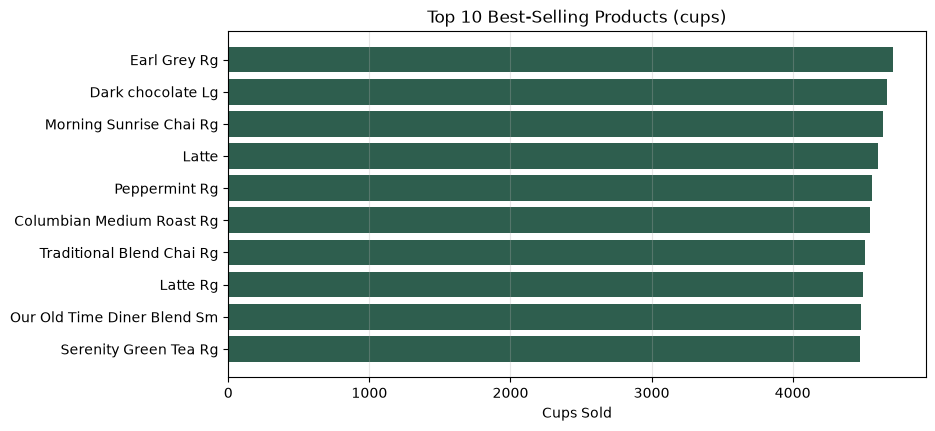

In [3]:
# คำถาม 1: สินค้า (ระดับ product_detail) ที่ขายได้ถึงแก้วมากที่สุด
top_cups = coffee.groupby("product_detail")["transaction_qty"].sum().sort_values(ascending=False)
print(top_cups.head(10))
print()
print("สินค้าขายดีที่สุด:", top_cups.idxmax(), "=", top_cups.max(), "แก้ว")

top10 = top_cups.head(10).sort_values()
plt.figure(figsize=(9, 4.5))
plt.barh(top10.index, top10.values, color="#2E5E4E")
plt.title("Top 10 Best-Selling Products (cups)")
plt.xlabel("Cups Sold")
plt.grid(True, axis="x", alpha=0.3)
plt.show()

## ขั้นที่ 3 · ตอบคำถามที่ 2 — สาขาไหนชนะ

เคล็ดลับใหม่ในเซลล์นี้: ตารางผลลัพธ์จาก pandas สั่งวาดกราฟได้ตรง ๆ ด้วย `.plot(kind="bar")` — pandas เรียก pyplot ให้เบื้องหลัง นี่แหละคือที่มาของชื่อหน่วย "pandas และ pyplot ทำงานร่วมกัน" 

store_location
Hell's Kitchen     236511.0
Astoria            232244.0
Lower Manhattan    230057.0
Name: revenue, dtype: float64

สาขาที่รายได้สูงสุด: Hell's Kitchen
เฉลี่ยต่อธุรกรรมของแต่ละสาขา:
store_location
Astoria            4.59
Hell's Kitchen     4.66
Lower Manhattan    4.81
Name: revenue, dtype: float64


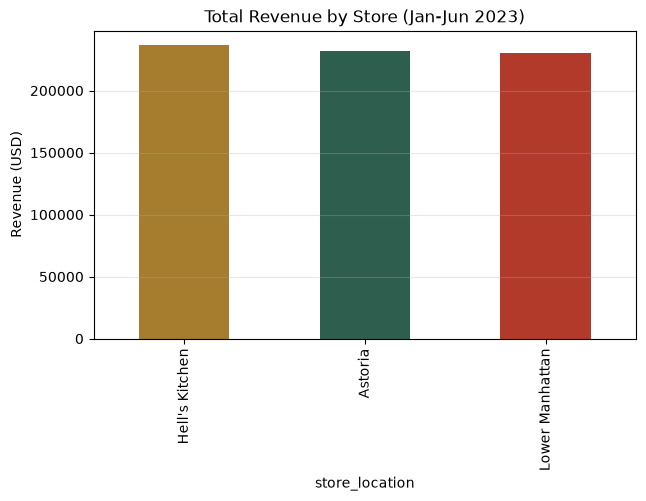

In [4]:
# คำถาม 2: รายได้แยกตามสาขา + ต่างกันเท่าไร
by_branch = coffee.groupby("store_location")["revenue"].sum().sort_values(ascending=False)
print(by_branch.round(0))
print()
diff = by_branch.iloc[0] - by_branch.iloc[-1]
print("สาขาที่รายได้สูงสุด:", by_branch.idxmax())
print("เฉลี่ยต่อธุรกรรมของแต่ละสาขา:")
print(coffee.groupby("store_location")["revenue"].mean().round(2))

by_branch.plot(kind="bar", color=["#A67C2E", "#2E5E4E", "#B23A2B"], figsize=(7, 4))
plt.title("Total Revenue by Store (Jan-Jun 2023)")
plt.ylabel("Revenue (USD)")
plt.grid(True, axis="y", alpha=0.3)
plt.show()

## ขั้นที่ 4 · ตอบคำถามที่ 3 — แนวโน้มรายเดือน

ข้อมูลวันที่อยู่ในคอลัมน์ `transaction_date` รูปแบบ **วัน-เดือน-ปี** (`01-01-2023` = 1 ม.ค. 2023) — ต้องแปลงเป็นวันที่จริงด้วย `pd.to_datetime()` ระบุ `format="%d-%m-%Y"` ก่อน แล้วดึงเดือนด้วย `.dt.month`

เคล็ดลับของเซลล์นี้คือ `unstack()`: จับกลุ่มด้วยสองคีย์ (เดือน + สาขา) แล้ว "กาง" สาขาออกเป็นคอลัมน์ เพื่อวาดเส้นเทียบกันได้ในคำสั่งเดียว

store_location  Astoria  Hell's Kitchen  Lower Manhattan
month                                                   
1               27314.0         27821.0          26543.0
2               25105.0         25720.0          25320.0
3               32835.0         33111.0          32889.0
4               39478.0         40304.0          39159.0
5               52429.0         52599.0          51700.0
6               55083.0         56957.0          54446.0


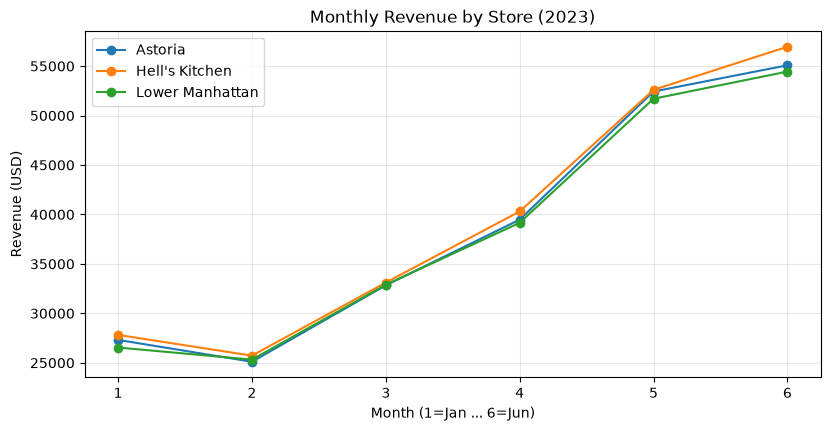

In [5]:
# คำถาม 3: แนวโน้มรายเดือนของแต่ละสาขา
coffee["month"] = pd.to_datetime(coffee["transaction_date"], format="%d-%m-%Y").dt.month

monthly = coffee.groupby(["month", "store_location"])["revenue"].sum().unstack()
print(monthly.round(0))

monthly.plot(kind="line", marker="o", figsize=(9.5, 4.5))
plt.title("Monthly Revenue by Store (2023)")
plt.xlabel("Month (1=Jan ... 6=Jun)")
plt.ylabel("Revenue (USD)")
plt.xticks(monthly.index)
plt.grid(True, alpha=0.3)
plt.legend(title="")
plt.show()

# สังเกต: ทั้ง 3 สาขายอดพุ่งขึ้นเรื่อย ๆ ถึงเดือน มิ.ย. — ฤดูร้อน + นักท่องเที่ยว!
# ถ้าเป็นที่ปรึกษาจริง เราจะตั้งคำถามต่อว่า ก.ค. จะยังโตอยู่ไหม ต้องเก็บข้อมูลต่อ

## 🎯 ภารกิจบทที่ 6 (ส่งคำตอบใน Moodle)

จากขั้นที่ 3 **รายได้รวมของสาขาที่ทำรายได้สูงสุด** ตลอด 6 เดือน เท่ากับกี่ดอลลาร์ (ปัดเป็นจำนวนเต็ม)

*ใบ้: `coffee.groupby("store_location")["revenue"].sum().max()` แล้ว `round()`*

In [6]:
# ภารกิจ 6: รายได้รวมของสาขาที่รายได้สูงสุด (จำนวนเต็มดอลลาร์)
top_branch_rev = coffee.groupby("store_location")["revenue"].sum().max()
print("สาขารายได้สูงสุด:", coffee.groupby("store_location")["revenue"].sum().idxmax())
print("คำตอบภารกิจบทที่ 6 =", round(top_branch_rev))

สาขารายได้สูงสุด: Hell's Kitchen
คำตอบภารกิจบทที่ 6 = 236511
